# Face Recognition

## 1. 개요 및 시스템 구조

Face Recognition은 얼굴 이미지에서 주요 특징점(landmark)을 검출하여 이를 이용해 사람을 구분하는 컴퓨터 비전 기술입니다.

YOLO Face 모델과 ms1mv2 모델을 사용하여 사람의 얼굴을 인식 인식합니다.

일반적으로 얼굴의 눈, 코, 입의 위치를 포함하여 약 5~68(혹은 그이상 106, 468)개의 주요 지점을 검출하는데, landmark point는 모델에 따라 다릅니다.

### 전체 처리 파이프라인
1. **이미지/비디오 입력**
2. **전처리** : 입력을 모델에 맞게 Resize, Padding을 하는 단계
3. **Face Box, Landmark NPU 추론** : 모델 추론으로 Face Box와 Landmark를 얻는 단계
4. **후처리** : 추론 결과를 Decoding 하고, NMS를 통해 한 얼굴에 한 결과를 결정하는 단계
5. **Face Alignment** : 얼굴을 Landmark를 기준으로 Resizing하고 Feature Extract 모델에 맞도록 눈, 코, 입을 정렬하는 단계
6. **Face Feature Extraction NPU 추론** : 얼굴의 Feature Vector를 모델 추론을 통해 추출하는 단계
7. **Cosine Similarity 계산 및 얼굴 인식** : 두 얼굴의 유사도를 Feature Vector의 Cosine Similarity로 계산하여 동인 일물인지 판별하는 단계

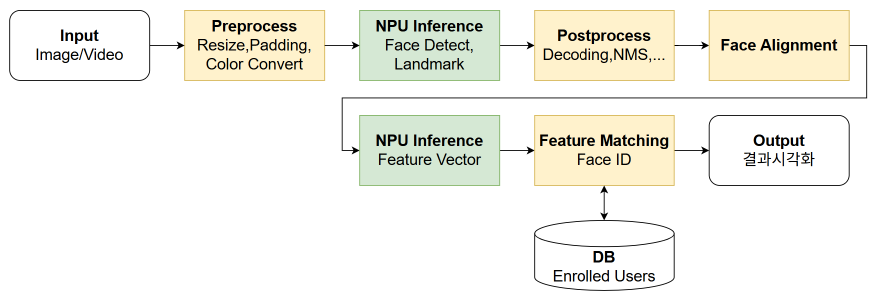

## 2-1. 모델 설명: YOLOV5S_Face-1.dxnn

사진에서 얼굴의 위치와 Landmark를 검출하는 모델입니다.

```bash
$ parse_model -m ./assets/models/YOLOV5S_Face-1.dxnn
modelPath: ./assets/models/YOLOV5S_Face-1.dxnn
.dxnn File Format Version : 6
Compiler Version : 1.60.1
RMapInfo Version : 2.30.1(M-master)
Loaded model infomation
  Task[0] cpu_1, CPU, memory-usage 2457600 bytes (input 1228800, output 1228800)
    inputs
      Im2col_input, UINT8, [1, 640, 640, 3 ], 0
    outputs
      input.1, UINT8, [1, 640, 1920 ], 0
  Task[0] npu_0, NPU, memory-usage 23458624 bytes (input 1228800, output 1612800)
    inputs
      input.1, UINT8, [1, 640, 1920 ], 0
    outputs
      /model.23/m.0/Conv_output_0, FLOAT, [1, 80, 80, 48 ], 0
      /model.23/m.2/Conv_output_0, FLOAT, [1, 20, 20, 48 ], 0
      /model.23/m.1/Conv_output_0, FLOAT, [1, 40, 40, 48 ], 0
  Task[0] cpu_0, CPU, memory-usage 3225600 bytes (input 1612800, output 1612800)
    inputs
      /model.23/m.0/Conv_output_0, FLOAT, [1, 80, 80, 48 ], 0
      /model.23/m.2/Conv_output_0, FLOAT, [1, 20, 20, 48 ], 0
      /model.23/m.1/Conv_output_0, FLOAT, [1, 40, 40, 48 ], 0
    outputs
      704, FLOAT, [1, 25200, 16 ], 0
```

### 입출력 텐서 구조
- **입력 텐서**: `images` - UINT8, [1, 640, 640, 3]
- **출력 텐서**: `704` - FLOAT, [1, 25200, 16]

### 출력 텐서 구조 분석

| **Index** | **Field** | **개수** | **설명** | **dtype** |
|:----------:|:-----------|:--------:|:-----------|:-----------|
| **0** | `cx` | 1 | 예측된 바운딩 박스 중심의 x 좌표 (픽셀 단위 또는 정규화) | `float32` |
| **1** | `cy` | 1 | 예측된 바운딩 박스 중심의 y 좌표 | `float32` |
| **2** | `w` | 1 | 예측된 바운딩 박스의 너비 | `float32` |
| **3** | `h` | 1 | 예측된 바운딩 박스의 높이 | `float32` |
| **4** | `objectness` | 1 | 해당 grid cell에 얼굴이 존재할 확률 | `float32` |
| **5 ~ 14** | `class probabilities` | 10 | Landmark의 (x, y) 좌표 | `float32 × 10` |
| **15** | `Class Label` | 1 | Class Number (Person) | `float32` |


## 2-2. 모델 설명: ms1mv2_r50_pfc_dxcom_v1.38.1.dxnn

두 얼굴을 비교하기 위해 얼굴의 Feature Vector를 출력하는 모델입니다.

```bash
$ parse_model -m ./assets/models/ms1mv2_r50_pfc_dxcom_v1.38.1.dxnn
modelPath: ./assets/models/ms1mv2_r50_pfc_dxcom_v1.38.1.dxnn
.dxnn File Format Version : 6
Compiler Version : 1.38.1
RMapInfo Version : 2.26.0(M-master)
Loaded model infomation
  Task[0] cpu_1, CPU, memory-usage 80640 bytes (input 37632, output 43008)
    inputs
      Im2col_input, UINT8, [1, 112, 112, 3 ], 0
    outputs
      input.1, UINT8, [1, 112, 384 ], 0
  Task[0] npu_0, NPU, memory-usage 44149376 bytes (input 43008, output 2048)
    inputs
      input.1, UINT8, [1, 112, 112, 3 ], 0
    outputs
      DX_tensor_1020, FLOAT, [1, 1, 1, 512 ], 0
  Task[0] cpu_0, CPU, memory-usage 4096 bytes (input 2048, output 2048)
    inputs
      DX_tensor_1020, FLOAT, [1, 512 ], 0
    outputs
      683, FLOAT, [1, 512 ], 0
```

### 입출력 텐서 구조
- **입력 텐서**: `Im2col_input` - UINT8, [1, 112, 112, 3]
- **출력 텐서**: `683` - FLOAT, [1, 512]


### 라이브러리 Import

- os : 결과 저장
- OpenCV, NumPy : 이미지 처리
- dx_engine : DX Runtime NPU 추론 엔진

In [ ]:
import os
import cv2
import numpy as np
from dx_engine import InferenceEngine, InferenceOption

## 3. 전처리 과정

### Input Preprocess

입력받은 img를 전처리하는 함수입니다.

**모델에 맞게 Resize, Padding, 색상정보를 변환** 합니다.

In [ ]:
def preprocess(image_src, new_shape=(640, 640), fill_color=(114, 114, 114), format=cv2.COLOR_BGR2RGB):
    # 이미지 크기를 모델 입력 크기에 맞추되, 원본 비율을 유지하며 padding을 추가하는 전처리 함수
    # image_src: 입력 이미지 (numpy array, BGR)
    # new_shape: 원하는 출력 크기 (기본 640x640)
    # fill_color: padding 시 채울 색상 (기본 [114,114,114] = 회색)
    # format: 색상 공간 변환 코드

    # 원본 이미지의 높이, 너비
    src_shape = image_src.shape[:2]  # (height, width)

    # new_shape이 int라면 pair로 변환
    if isinstance(new_shape, int):
        new_shape = (new_shape, new_shape)

    # 축소/확대 비율 계산 (세로와 가로 중 더 작은 비율 선택 → 종횡비 유지)
    r = min(new_shape[0] / src_shape[0], new_shape[1] / src_shape[1])
    ratio = r, r

    # padding 없이 리사이즈했을 때의 크기
    new_unpad = int(round(src_shape[1] * r)), int(round(src_shape[0] * r))

    # 남는 공간(padding 크기) 계산
    dw, dh = new_shape[1] - new_unpad[0], new_shape[0] - new_unpad[1]

    # padding은 좌우/상하 균등하게 분배
    dw /= 2
    dh /= 2

    # 종횡비가 다르면 resize 실행
    if src_shape[::-1] != new_unpad:
        image_src = cv2.resize(image_src, new_unpad, interpolation=cv2.INTER_LINEAR)

    # 실제 padding 적용 (top, bottom, left, right)
    top, bottom = int(round(dh - 0.1)), int(round(dh + 0.1))
    left, right = int(round(dw - 0.1)), int(round(dw + 0.1))
    image_new = cv2.copyMakeBorder(
        image_src, top, bottom, left, right,
        cv2.BORDER_CONSTANT, value=fill_color
    )

    # 색상 변환
    if format is not None:
        image_new = cv2.cvtColor(image_new, format)

    # 전처리된 이미지, resize 비율, padding 크기 반환
    return image_new, ratio, (dw, dh)

## 4. 후처리 과정

### Onnx Runtime 미사용시

Onnx Runtime을 사용하지 않으면 모델 추론에서 CPU부분을 코드로 직접 구현해야 합니다.

아래는 NPU로 추론후에 나온 Onnx Output을 직접 포스트프로세싱해서 (25200,16) 으로 만드는 함수입니다.

구현 과정은 DX_Tron으로 모델을 관찰하며 어떤 과정이 진행되는지 직접 구현합니다.

```bash

  Task[0] npu_0, NPU, memory-usage 23458624 bytes (input 1228800, output 1612800)
    inputs
      input.1, UINT8, [1, 640, 1920 ], 0
    outputs
      /model.23/m.0/Conv_output_0, FLOAT, [1, 80, 80, 48 ], 0
      /model.23/m.2/Conv_output_0, FLOAT, [1, 20, 20, 48 ], 0
      /model.23/m.1/Conv_output_0, FLOAT, [1, 40, 40, 48 ], 0


```

80 -> 20 -> 40 순으로 3개의 앵커박스의 정보와 stride를 이용하여 한 박스당 16개의 output으로 변환합니다.

예시 = 80 x 80 x 48 => 80(grid 가로 개수) x 80(grid 세로 개수) x 3(Anchor 수) x 16 

최종 output = (25200, 16)

In [ ]:
num_anchors = 3
anchors = [
    np.array([[4,5],  [8,10],  [13,16]]),   
    np.array([[146,217],  [231,300],  [335,433]]),
    np.array([[23,29],  [43,55],  [73,105]])  
]
strides = [8, 32, 16]

def sigmoid_np(x):
    x = np.clip(x, -88.0, 88.0, dtype=np.float64)
    return 1.0 / (1.0 + np.exp(-x, dtype=np.float64))

def face_yolo_postprocess_numpy(outputs, anchors, strides):
    batch = outputs[0].shape[0]
    processed = []

    for idx, output in enumerate(outputs):
        h, w = output.shape[1], output.shape[2]
        stride = np.float32(strides[idx])
        anchor = anchors[idx].astype(np.float32)
        num_anchors = anchor.shape[0]

        # (1, H, W, 3, 16)
        output = output.astype(np.float32).reshape(batch, h, w, num_anchors, 16)

        # Sigmoid 적용
        output[..., 0:2] = sigmoid_np(output[..., 0:2])   # cx, cy
        output[..., 2:4] = sigmoid_np(output[..., 2:4])   # w, h
        output[..., 4]   = sigmoid_np(output[..., 4])     # obj conf
        output[..., 15]  = sigmoid_np(output[..., 15])    # face prob (label)

        grid_x, grid_y = np.meshgrid(np.arange(w, dtype=np.float32),
                                     np.arange(h, dtype=np.float32))
        grid = np.stack((grid_x, grid_y), axis=-1) 

        xy = ((output[..., 0:2] * 2.0) - 0.5 + grid[None, ..., None, :]) * stride
        wh = ((output[..., 2:4] * 2.0) ** 2) * anchor[None, None, None, :, :]

        lm = output[..., 5:15].reshape(batch, h, w, num_anchors, 5, 2)

        lm = (lm * anchor[None, None, None, :, None, :]) + (grid[None, :, :, None, None, :] * stride)

        # concat [cx, cy, w, h, score, landmarks(10), face_prob]
        box = np.concatenate(
            (
                xy,                            # (2)
                wh,                            # (2)
                output[..., 4:5],                 # (1)
                lm.reshape(batch, h, w, num_anchors, 10),  # (10)
                output[..., 15:16],            # (1)
            ),
            axis=-1,
        )  # total = 16 channels again

        # (1, H*W*3, 16)
        box = box.reshape(batch, -1, 16).astype(np.float32)
        processed.append(box)

    # (1, total, 16)
    return np.concatenate(processed, axis=1).astype(np.float32)

### Output Decoding

Yolo Face Model을 통해 추론한 얼굴 Box와 5개의 Landmark를 후처리하는 함수입니다.

Output : (1, 25200, ***16***)

| **Index** | **Field** | **개수** | **설명** | **dtype** |
|:----------:|:-----------|:--------:|:-----------|:-----------|
| **0** | `cx` | 1 | 예측된 바운딩 박스 중심의 x 좌표 (픽셀 단위 또는 정규화) | `float32` |
| **1** | `cy` | 1 | 예측된 바운딩 박스 중심의 y 좌표 | `float32` |
| **2** | `w` | 1 | 예측된 바운딩 박스의 너비 | `float32` |
| **3** | `h` | 1 | 예측된 바운딩 박스의 높이 | `float32` |
| **4** | `objectness` | 1 | 해당 grid cell에 얼굴이 존재할 확률 | `float32` |
| **5 ~ 14** | `class probabilities` | 10 | Landmark의 (x, y) 좌표, 5x2 | `float32 × 10` |
| **15** | `Class Label` | 1 | Class Number (Person) | `float32` |

#### 5개의 Landmark
```
0: 왼쪽 눈
1: 오른쪽 눈
2: 코
3: 왼쪽 입꼬리
4: 오른쪽 입꼬리
```

In [ ]:
def decode(ie_output_dict, score_threshold=0.25, kpt_count=5):
    # ie_output_dict: 추론 엔진에서 나온 결과
    # score_threshold: 얼굴을 검출할 최소 confidence 값
    # kpt_count: 사용할 keypoint 개수 (기본 5개: 눈, 코, 입꼬리)

    # list -> np.ndarray
    ie_output = ie_output_dict[0]
    # 배치 차원 제거
    ie_output = ie_output[0]

    decoded_tensor = []
    for det in ie_output:
        # det = [cx, cy, w, h, score, kpt1_x, kpt1_y, ..., kpt5_x, kpt5_y, label]
        score = float(det[4])  # confidence 값
        if score < score_threshold:
            # confidence가 threshold보다 낮으면 무시
            continue

        box = det[0:4]                   # 바운딩 박스 정보 (cx, cy, w, h)
        kpts = det[5:5 + kpt_count*2]    # keypoints 좌표 (x, y) * kpt_count
        label = int(det[-1])             # 클래스 레이블 (마지막 값)

        # [box(4), score(1), keypoints(2*kpt_count)] 형태의 텐서 생성
        tensor = np.zeros((5 + kpt_count*2), dtype=float)
        tensor[:4] = box                 # 바운딩 박스 저장
        tensor[4] = score                # score 저장
        tensor[5:5+kpt_count*2] = kpts   # keypoints 저장
        decoded_tensor.append(tensor)    # 결과 리스트에 추가

    if len(decoded_tensor) == 0:
        # 얼굴이 검출되지 않았다면 0으로 채워진 벡터 반환
        return np.zeros((5 + kpt_count*2), dtype=float)

    # 리스트를 numpy 배열로 변환
    return np.stack(decoded_tensor)

### NMS (Non-Maximum Suppression) 적용

중복되는 검출 박스를 제거하고 최적의 검출 결과만 유지합니다.

In [ ]:
def nms(dets, iou_thr=0.5):
    """
    Args:
        dets: ndarray [N, 6]
              (x1, y1, x2, y2, score, label)
              - (x1, y1): 좌상단 좌표
              - (x2, y2): 우하단 좌표
              - score: confidence 점수
              - label: 클래스 라벨
        iou_thr: IoU threshold (겹침 정도 기준, 기본값 0.5)

    Returns:
        keep: 선택된 박스들의 index 리스트
    """

    if len(dets) == 0:
        return dets  # 박스가 없으면 그대로 반환

    # 좌표와 점수, 레이블 분리
    x1, y1, x2, y2, scores, labels = (
        dets[:, 0], dets[:, 1], dets[:, 2], dets[:, 3], dets[:, 4], dets[:, 5]
    )

    keep = []  # 최종 선택된 박스 인덱스 저장
    # 점수(score)가 큰 순서대로 정렬된 인덱스
    idxs = scores.argsort()[::-1]

    while len(idxs) > 0:
        # 현재 가장 점수가 높은 박스 선택
        i = idxs[0]
        keep.append(i)

        # 선택된 박스(i)와 나머지 박스들 간의 좌표 비교
        xx1 = np.maximum(x1[i], x1[idxs[1:]])
        yy1 = np.maximum(y1[i], y1[idxs[1:]])
        xx2 = np.minimum(x2[i], x2[idxs[1:]])
        yy2 = np.minimum(y2[i], y2[idxs[1:]])

        # 겹치는 영역(intersection) 계산
        w = np.maximum(0.0, xx2 - xx1)
        h = np.maximum(0.0, yy2 - yy1)
        inter = w * h

        # union = (각 영역 넓이 합 - 교집합 넓이)
        union = ((x2[i]-x1[i]) * (y2[i]-y1[i]) +
                 (x2[idxs[1:]]-x1[idxs[1:]]) * (y2[idxs[1:]]-y1[idxs[1:]]) - inter)

        # IoU(Intersection over Union) 계산
        iou = inter / (union + 1e-6)

        # IoU가 threshold 이하인 것만 남김 (겹침이 심한 박스는 제거)
        idxs = idxs[1:][iou <= iou_thr]

    return keep

## 5. Face Alignment

**ms1mv2_r50_pfc_dxcom_v1.38.1.dxnn** 모델을 사용하여 얼굴의 Feature를 추출하기 위해 모델에 맞도록 얼굴 이미지를 변환해줘야 합니다.

모델은 input으로 112 x 112 x 3 이미지를 입력받습니다.

Landmark의 위치를 기반으로 image에서 얼굴을 112 x 112 사이즈로 정렬해서 추출하는 함수입니다.

**예시 이미지**

Original에서는 두 눈의 높이가 맞지 않는데, 이를 같은 높이로 정렬한 것을 확인할 수 있습니다.

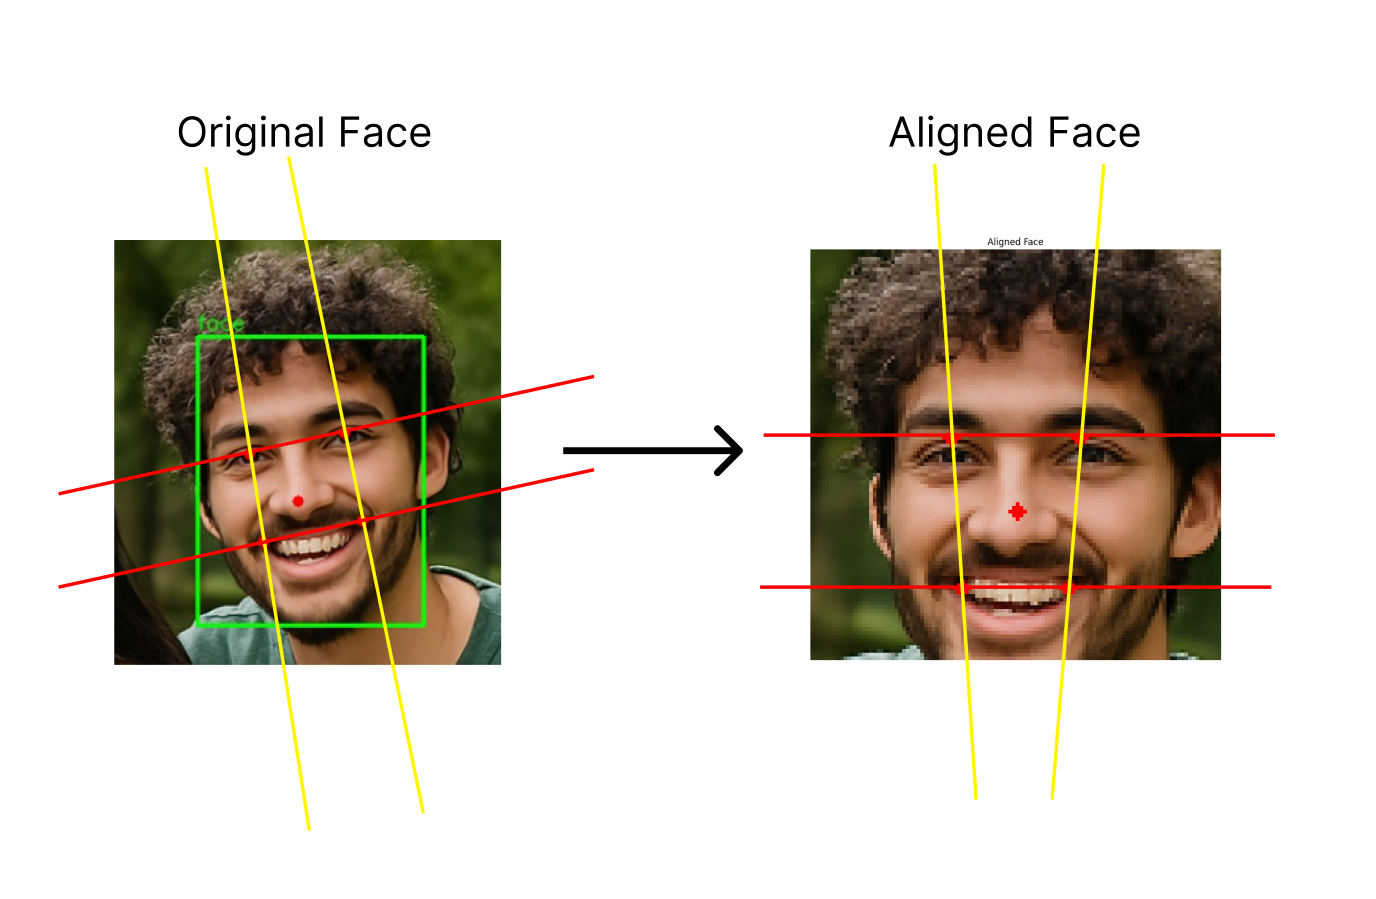



In [ ]:
def warp_face(img, landmarks):
    # 얼굴 정렬 함수 (Face Alignment)
    # 입력된 얼굴 랜드마크를 기준 좌표에 맞게 변환하여
    # 동일한 크기(112x112)로 정렬된 얼굴 이미지를 생성한다.

    # src_points: 입력 이미지에서 검출된 랜드마크 좌표 (5개 점: 눈, 코, 입 양쪽)
    src_points = np.array(landmarks, dtype=np.float32)  # shape = (5, 2)

    # dst_points: 정렬 기준이 되는 표준 얼굴 랜드마크 좌표
    # (112x112 크기에서의 기준 위치, 보통 학습 데이터셋에서 정의)
    dst_points = np.array([
        [38.2946, 51.6963],   # 왼쪽 눈
        [73.5318, 51.5014],   # 오른쪽 눈
        [56.0252, 71.7366],   # 코
        [41.5493, 92.3655],   # 왼쪽 입
        [70.7299, 92.2041],   # 오른쪽 입
    ], dtype=np.float32)

    # 입력 랜드마크(src_points) → 기준 랜드마크(dst_points)로 맞추는
    # Affine 변환 행렬 M 계산 (scale, rotation, translation 포함)
    M, _ = cv2.estimateAffinePartial2D(src_points, dst_points)

    # img를 변환 행렬 M으로 warp → 112x112 크기로 맞춘 얼굴 이미지 생성
    aligned = cv2.warpAffine(img, M, (112, 112))

    return aligned  # 정렬된 얼굴 이미지 반환

## 6. 코사인 유사도 (Cosine Similarity)

코사인 유사도는 **두 벡터 간의 방향(각도)을 이용해 얼마나 유사한지를 측정하는 지표**입니다.  

### 수식

Cosine Similarity = (A · B) / (||A|| × ||B||)

### 유사도 값

| 코사인 유사도 값 | 의미 |
|------------------|------|
| **1** | 두 벡터의 방향이 거의 같음 (매우 유사) |
| **0** | 두 벡터가 직교 (무관함) |
| **-1** | 두 벡터의 방향이 반대 (완전히 다름) |

코사인 유사도를 통해 두 얼굴의 Feature Vector가 얼마나 유사한지 확인합니다.

In [ ]:
def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6)

## 7. Feature Extract

입력 이미지를 Feature Vector로 변환하는 전체 과정을 수행하는 함수입니다.

### 실행 구조

1. 이미지 전처리
2. 얼굴 및 Landmark 검출
3. 모델 출력 후처리
4. Landmark 기반 정렬
5. 얼굴 Feature 추출

In [ ]:
def extract_feature(ie, ie_recog, frame):
    """
    얼굴 특징(embedding) 벡터를 추출하는 함수
    1) 얼굴 검출 → 2) NMS → 3) 랜드마크 기반 정렬 → 4) 얼굴 임베딩 추출
    """

    score_threshold = 0.25     # 얼굴 검출 최소 confidence
    iou_threshold = 0.4        # NMS에서 사용할 IoU 임계값
    kpt_count = 5              # 사용할 keypoint 개수 (왼쪽 눈, 오른쪽 눈, 코, 입 양쪽)

    # (1) 얼굴 검출 모델 입력 크기 계산
    #(ie.get_input_size() = 모델 입력 크기(H*W*C)
    input_size = int(np.sqrt(ie.get_input_size() / 3))

    # (2) 입력 이미지를 모델 입력 크기에 맞게 전처리
    # - 비율 유지 resize + padding + 색상공간 변환(BGR → RGB)
    image_input, ratio, pad = preprocess(
        frame, new_shape=(input_size, input_size),
        fill_color=(114, 114, 114), format=cv2.COLOR_BGR2RGB
    )

    # use_ort == False 일 경우, NPU에 Input으로 바로 넣기 위해 Reshape이 필요하나, 메모리 상 동일하므로 생략 가능
    # if(io.get_use_ort()==False):
    #     image_input = image_input.astype(np.uint8).reshape(1, input_size, input_size*3)

    # (3) 얼굴 검출 모델 실행
    ie_output = (ie.run([image_input]))
    
    if(io.get_use_ort()==False):  # ONNX Runtime 사용 시 후처리 필요
        #print("Using DX Engine")
        ie_output1 = face_yolo_postprocess_numpy(
            ie_output, anchors=anchors, strides=strides
        )
    else:
        #print("Using ONNX Runtime")
        ie_output1 = ie_output[0]
    
    # (4) 모델 출력 후처리 → 바운딩박스, score, keypoints 추출
    decoded_tensor = decode(
        ie_output1, score_threshold=score_threshold, kpt_count=kpt_count
    )

    # (5) 차원 축소 (불필요한 차원 제거)
    x = np.squeeze(decoded_tensor)
    if x.ndim == 1:
        # 검출된 얼굴이 없을 경우
        return None

    # (6) confidence(score) 기준 필터링
    x = x[x[..., 4] > score_threshold]
    if x.shape[0] == 0:
        return None

    # (7) 바운딩 박스와 keypoints 정리
    all_dets = []
    for det in x:
        cx, cy, w, h, conf = det[:5]  # 중심좌표(cx, cy), 폭, 높이, confidence
        x1, y1 = cx - w / 2, cy - h / 2
        x2, y2 = cx + w / 2, cy + h / 2
        kpts = det[5:5 + kpt_count*2].reshape(kpt_count, 2)  # keypoints 좌표 (5개 점)
        # [x1, y1, x2, y2, score, label, keypoints...] 형태로 저장
        all_dets.append([x1, y1, x2, y2, conf, 0, *kpts.flatten()])
    all_dets = np.array(all_dets)

    # (8) NMS 적용 → 겹치는 박스 제거, score 높은 것만 남김
    keep = nms(all_dets[:, :6], iou_thr=iou_threshold)
    final_dets = all_dets[keep]

    # (9) 원본 이미지 크기 (좌표 보정에 필요)
    h, w = frame.shape[:2]
    results = []  # 최종 얼굴 특징과 bbox를 담을 리스트

    # (10) 검출된 얼굴 후보들 반복 처리
    for det in final_dets:
        kpts = det[6:].reshape(kpt_count, 2)  # (5,2) keypoints 좌표

        # (11) padding, resize 비율을 보정하여 원본 이미지 좌표로 변환
        landmarks = []
        for (kx, ky) in kpts:
            px = int((kx - pad[0]) / ratio[0])
            py = int((ky - pad[1]) / ratio[1])
            # 이미지 경계 밖으로 나가지 않도록 제한
            px = np.clip(px, 0, w-1)
            py = np.clip(py, 0, h-1)
            landmarks.append((px, py))

        # (12) 랜드마크를 기준으로 얼굴 정렬 (112x112 크기)
        aligned_face = warp_face(frame, landmarks)

        # (13) 얼굴 인식 모델 입력 크기에 맞게 reshape (배치 차원 포함)
        fr_input = aligned_face.astype(np.uint8).reshape(1, 112, 112, 3)

        if(io.get_use_ort()==False):
            
            #resshape 1x112x336
            fr_input = fr_input.astype(np.uint8).reshape(1, 112, 336)

            zeros = np.zeros((1, 112, 48), dtype=fr_input.dtype)

            fr_input = np.concatenate((fr_input, zeros), axis=2)

        # (14) 얼굴 인식 모델 실행 → 임베딩 벡터(128D, 512D 등) 추출
        fr_outputs = ie_recog.run([fr_input])

        if(io.get_use_ort()==False):
            fr_outputs = np.squeeze(fr_outputs[0]).reshape(1, 512)
            # print("here")

            feat = feature_postprocess_numpy(fr_outputs)
            feat = np.array(feat, copy=False).reshape(-1)
            feat = feat / np.linalg.norm(feat)
        else:
            # print("Using ONNX Runtime for feature extraction")
            # print("fr_outputs[0] shape:", fr_outputs[0].shape)
            feat = np.array(fr_outputs[0], copy=False).reshape(-1)
            feat = feat / np.linalg.norm(feat)
        # print("feat example:", feat, "... (len=", len(feat), ")")

        # (15) 특징 벡터와 바운딩 박스를 함께 저장
        x1, y1, x2, y2 = det[:4]
        # 좌표를 원본 이미지에 맞게 보정
        x1 = int(((x1) - pad[0]) / ratio[0])
        y1 = int(((y1) - pad[1]) / ratio[1])
        x2 = int(((x2) - pad[0]) / ratio[0])
        y2 = int(((y2) - pad[1]) / ratio[1])
        x1 = np.clip(x1, 0, w - 1)
        y1 = np.clip(y1, 0, h - 1)
        x2 = np.clip(x2, 0, w - 1)
        y2 = np.clip(y2, 0, h - 1)

        results.append({"feat": feat, "bbox": (x1, y1, x2, y2)})

    # (16) 모든 얼굴 특징 + bbox 리스트 반환 (없으면 None 반환)
    return results if len(results) > 0 else None

### Onnx Runtime 사용하지 않는 경우를 위한 feature postprocess 함수

add1, mul1, add2 는 사전 학습된 모델의 weight

In [ ]:
add1 = np.load("./assets/weights/add1.npy")
mul1 = np.load("./assets/weights/mul1.npy")
add2 = np.load("./assets/weights/add2.npy")

def feature_postprocess_numpy(features):
    """
    features: np.ndarray, shape [1, 512]
    순서: add1 → mul1 → add2
    """

    features = (features + add1) * mul1 + add2
    
    return features.astype(np.float32)

## 8. Gallery 구축

얼굴 인식을 통해 사람을 구분하려면, 기준이 되는 얼굴이 있어야 합니다.

특정 폴더에 있는 사진을 바탕으로 카메라 입력과 비교할 feature의 모음을 만드는 함수입니다.

In [ ]:
def build_gallery(ie_align, ie_recog, image_paths):
    """
    갤러리(등록된 얼굴 데이터베이스)를 구축하는 함수
    - 주어진 폴더 내 이미지에서 얼굴 특징 벡터 추출
    - 각 얼굴에 랜덤 색상 지정
    - 반환 형식: {이름: {"feat": 특징벡터, "color": (B,G,R)}}
    """

    gallery = {}  # 최종적으로 반환할 딕셔너리

    # (1) 폴더 내 파일들 순회
    for fname in os.listdir(image_paths):
        fpath = os.path.join(image_paths, fname)
        img = cv2.imread(fpath)  # 이미지 읽기
        if img is None:
            # 이미지 파일을 읽을 수 없는 경우
            print(f"[WARNING] Could not read image {fpath}, skipping.")
            continue

        # (2) 얼굴 특징 추출
        # extract_feature는 리스트를 반환하며, 각 원소는 {"feat": ..., "bbox": ...} 구조
        results = extract_feature(ie_align, ie_recog, img)

        if results is not None and len(results) > 0:
            # 파일명에서 확장자 제거 → 이름으로 사용
            name, _ = os.path.splitext(fname)
            # 첫 번째 얼굴의 feature만 사용 (한 장에 얼굴 하나라고 가정)
            feat = results[0]["feat"]

            # (3) 랜덤 색상 생성 (0~255 범위에서 BGR 값 선택)
            color = tuple(np.random.randint(0, 256, size=3).tolist())

            # (4) gallery 딕셔너리에 저장
            # - key: 이름
            # - value: {"feat": 얼굴 임베딩 벡터, "color": 랜덤 색상}
            gallery[name] = {"feat": feat, "color": color}
            print(f"[INFO] Added {name} to gallery with random color {color}.")
        else:
            # 얼굴 검출 실패한 경우
            print(f"[WARNING] No face detected in {fpath}, skipping.")

    # (5) 모든 이미지 처리 후 반환
    return gallery

## 9. 얼굴 인식 실행

얼굴 인식을 실행하고, 결과 img를 반환하는 함수입니다.

In [ ]:
def run_inference_face(ie, ie_recog, frame, gallery,
                       kpt_count=5):
    """
    얼굴 인식 실행 함수
    - 입력 프레임에서 얼굴 검출 및 특징 벡터 추출 (extract_feature 호출)
    - 갤러리에 등록된 얼굴들과 cosine similarity로 비교
    - 가장 유사한 이름/스코어를 bbox 위에 표시
    """

    img_vis = frame.copy()

    # (1) 프레임에서 얼굴 특징 + bbox 추출
    results = extract_feature(ie, ie_recog, frame)
    if results is None or len(results) == 0:
        # 얼굴이 검출되지 않은 경우 → 원본 그대로 반환
        return img_vis

    # (2) 검출된 모든 얼굴에 대해 갤러리와 비교
    for res in results:
        feat = res["feat"]            # 얼굴 임베딩 벡터
        (x1, y1, x2, y2) = res["bbox"]  # 얼굴 바운딩 박스 좌표

        # (3) 갤러리와 cosine similarity 비교 → 가장 높은 점수 찾기
        best_name, best_score = "Unknown", 0.0
        for name, g_data in gallery.items():
            g_feat = g_data["feat"]
            sim = cosine_similarity(feat, g_feat)
            if sim > best_score:
                best_name, best_score = name, sim

        # (4) threshold(0.5) 이상이면 이름 + score 표시, 아니면 Unknown
        label = f"{best_name}:{best_score:.2f}" if best_score > 0.5 else "Unknown"

        # 색상 불러오기 (Unknown은 흰색)
        color = gallery[best_name]["color"] if best_name in gallery else (255, 255, 255)

        # (5) bbox와 label을 프레임에 그리기
        cv2.rectangle(img_vis, (x1, y1), (x2, y2), color, 2)
        cv2.putText(img_vis, label, (x1, y1 - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

    # (6) 결과 이미지 반환
    return img_vis


## 10. Run 함수

카메라를 통해 실시간으로 영상을 캡쳐해서 그 이미지를 추론하는 실행 함수 입니다.
```
[ WARN:0@0.953] global cap_v4l.cpp:914 open VIDEOIO(V4L2:/dev/video0): can't open camera by index
[ERROR:0@0.955] global obsensor_uvc_stream_channel.cpp:163 getStreamChannelGroup Camera index out of range
```

위와 같은 오류 발생 시 터미널에서 카메라 디바이스 확인하여 'cap = cv2.VideoCapture(**0**)' 부분을 적절히 수정
```
$ ls /dev/video*
/dev/video0  /dev/video1
```

실행된 웹캠 화면에서,

- c 입력 : 현재 화면을 캡쳐하여 Gallery에 추가
- d 입력 : Gallery에 있는 사진을 선택하여 삭제

In [ ]:
def run():
    """
    얼굴 검출 + 인식 실행 함수 (비디오 입력 전용)
    - 웹캠을 통해 실시간 얼굴 인식 수행
    - 'c' 키: 얼굴 캡처 후 갤러리에 저장
    - 'd' 키: 갤러리 이미지 삭제
    - 'q' 키: 종료
    """

    # (1) 모델 경로 설정
    model_path1 = "./assets/models/YOLOV5S_Face-1.dxnn"      # 얼굴 검출 모델
    model_path2 = "./assets/models/ms1mv2_r50_pfc_dxcom_v1.38.1.dxnn"  # 얼굴 인식 모델

    # (2) 추론 엔진 초기화
    ie = InferenceEngine(model_path1, io)
    ie_recog = InferenceEngine(model_path2, io)

    # (3) 갤러리 로드 (등록된 얼굴 DB)
    gallery = build_gallery(ie, ie_recog, "./assets/gallery")

    # (4) 웹캠 열기
    cap = cv2.VideoCapture(1)  # 기본 카메라 장치
    if not cap.isOpened():
        print("[ERROR] Cannot open webcam")
        exit(1)

    # (5) 루프 시작
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # 실시간 얼굴 인식 실행
        img_vis = run_inference_face(ie, ie_recog, frame, gallery)
        cv2.imshow("result", img_vis)

        key = cv2.waitKey(1) & 0xFF
        if key == ord('q'):  # 종료
            break

        # 'c' 키: 얼굴 캡처 후 갤러리에 저장
        elif key == ord('c'):
            # 프레임에서 얼굴 특징 추출
            results = extract_feature(ie, ie_recog, frame)

            if results is None or len(results) == 0:
                print("[CAPTURE] No face detected in frame")
                continue

            # 검출된 얼굴들 순회
            i = 1
            h, w = frame.shape[:2]
            for res in results:
                (x1, y1, x2, y2) = res["bbox"]

                # bbox 확장 (머리/턱 여유 공간 포함)
                bw = (x2 - x1) / 2 * 0.5   # bbox 폭의 절반 * 비율
                bh = (y2 - y1) / 2 * 0.5   # bbox 높이의 절반 * 비율
                x1 = max(0, int(x1 - bw))
                y1 = max(0, int(y1 - bh))
                x2 = min(w, int(x2 + bw))
                y2 = min(h, int(y2 + bh))
                face_crop = frame[y1:y2, x1:x2]

                if face_crop.size > 0:
                    win_name = f"Face {i}"
                    cv2.imshow(win_name, face_crop)
                    cv2.waitKey(1)

                    # 사용자에게 이름 입력받음
                    name = input(f"Enter name for face {i}: ").strip()
                    if not name:
                        name = f"face_{i}"
                    i += 1

                    # crop 얼굴 저장
                    save_path = os.path.join("./assets/gallery", f"{name}.jpg")
                    cv2.imwrite(save_path, face_crop)
                    print(f"[CAPTURE] Saved cropped face to {save_path}")

                    cv2.destroyWindow(win_name)
                else:
                    print(f"[CAPTURE] No valid face crop found for detection #{i}")

            # 갤러리 갱신
            gallery = build_gallery(ie, ie_recog, "./assets/gallery")


        # 'd' 키: 갤러리에서 이미지 삭제
        elif key == ord('d'):
            gallery_files = [f for f in os.listdir("./assets/gallery") if f.lower().endswith((".jpg", ".png"))]
            if not gallery_files:
                print("[DELETE] Gallery is empty.")
            else:
                print("\n[DELETE] Gallery Images:")
                for idx, fname in enumerate(gallery_files, start=1):
                    print(f"{idx}: {fname}")
                try:
                    sel = int(input("Enter number to delete: ").strip())
                    if 1 <= sel <= len(gallery_files):
                        del_path = os.path.join("./assets/gallery", gallery_files[sel-1])
                        os.remove(del_path)
                        print(f"[DELETE] Removed {del_path}")
                        gallery = build_gallery(ie, ie_recog, "./assets/gallery")
                    else:
                        print("[DELETE] Invalid number.")
                except ValueError:
                    print("[DELETE] Invalid input.")

    cap.release()
    cv2.destroyAllWindows()